# Лабораторная работа №1
## Введение и воспроизводимость исследований

**Вариант:** 10  
**Датасет:** Iris (`sklearn.datasets`)  
**Задача:** многоклассовая классификация видов ириса  
**Целевая переменная:** `target`  
**Кастомный трансформер:** отношение `petal_length / petal_width`

Цель работы — подготовить воспроизводимый ML-проект, применить Git и DVC,
создать конвейер обработки данных на основе `Pipeline` и `ColumnTransformer`,
обучить модель, оценить её и сохранить все результаты в структуре проекта.

## 1. Импорт библиотек и воспроизводимость

In [1]:
from pathlib import Path
import json
import platform
import subprocess
import sys
import warnings

import joblib
import cloudpickle
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
    classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (PROJECT_ROOT / ".git").exists():
    raise RuntimeError("Запустите Notebook из корня репозитория или каталога notebooks.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for directory in (RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Корень проекта: {PROJECT_ROOT}")
for name, version in {
    "Python": platform.python_version(), "NumPy": np.__version__,
    "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__, "joblib": joblib.__version__,
}.items():
    print(f"{name}: {version}")

Корень проекта: C:\Users\Доктор Варвар\Desktop\все\MWwithD
Python: 3.11.9
NumPy: 1.26.4
pandas: 2.2.3
scikit-learn: 1.5.2
matplotlib: 3.9.2
joblib: 1.4.2


## 2. Структура проекта

In [2]:
def print_tree(root: Path, max_depth: int = 3) -> None:
    """Печатает дерево без служебных каталогов."""
    ignored = {".git", ".dvc", ".venv", "__pycache__", ".ipynb_checkpoints"}
    print(root.name + "/")
    for path in sorted(root.rglob("*")):
        relative = path.relative_to(root)
        if len(relative.parts) > max_depth or any(p in ignored for p in relative.parts):
            continue
        print("    " * len(relative.parts) + relative.name + ("/" if path.is_dir() else ""))

print_tree(PROJECT_ROOT)

MWwithD/


    .dvcignore
    .gitignore
    data/
        DESCRIPTION.txt
        external/
            DESCRIPTION.txt
        processed/
            .gitignore
            DESCRIPTION.txt
            test.csv
            test.csv.dvc
            train.csv
            train.csv.dvc
        raw/
            .gitignore
            DESCRIPTION.txt
            iris_with_missing.csv
            iris_with_missing.csv.dvc
            sample_customers.csv.dvc
    models/
        .gitignore
        DESCRIPTION.txt
        iris_pipeline.pkl
        iris_pipeline.pkl.dvc
    notebooks/
        DESCRIPTION.txt
        lab1_iris_variant10.ipynb
        lab1_iris_variant10.py
    README.md
    reports/
        classification_report.csv
        DESCRIPTION.txt
        figures/
            class_distribution.png
            confusion_matrix.png
            correlation_matrix.png
            dvc_status.png
            feature_distributions.png
            metrics_summary.png
            missing_values.png
     

## 3. Загрузка датасета Iris

Iris содержит 150 объектов, четыре числовых признака и три класса. В исходном
датасете пропусков нет.

In [3]:
iris = load_iris(as_frame=True)
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df = iris.data.copy()
df.columns = feature_names
df["target"] = iris.target.astype(int)
print(f"Размер датасета: {df.shape}")
display(df.head())
display(df.describe().T)
display(df.isna().sum().to_frame("missing_count"))
display(df["target"].value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))

Размер датасета: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


,missing_count
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
target,0


target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 4. Искусственное внесение пропусков

По условию создаётся 10% пропусков в `sepal_length` и `petal_length`.

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
missing_columns = ["sepal_length", "petal_length"]
n_missing = int(round(len(df) * 0.10))
df_missing = df.copy()
for column in missing_columns:
    indices = rng.choice(df_missing.index, size=n_missing, replace=False)
    df_missing.loc[indices, column] = np.nan

missing_summary = pd.DataFrame({
    "missing_count": df_missing.isna().sum(),
    "missing_percent": (df_missing.isna().mean() * 100).round(2),
})
display(missing_summary)
assert df_missing[missing_columns].isna().sum().eq(n_missing).all()
assert df_missing["target"].notna().all()
raw_path = RAW_DIR / "iris_with_missing.csv"
df_missing.to_csv(raw_path, index=False)
print(f"Сохранено: {raw_path.relative_to(PROJECT_ROOT)}")

,missing_count,missing_percent
sepal_length,15,10.0
sepal_width,0,0.0
petal_length,15,10.0
petal_width,0,0.0
target,0,0.0


Сохранено: data\raw\iris_with_missing.csv


## 5. Исследовательский анализ и сохранение изображений

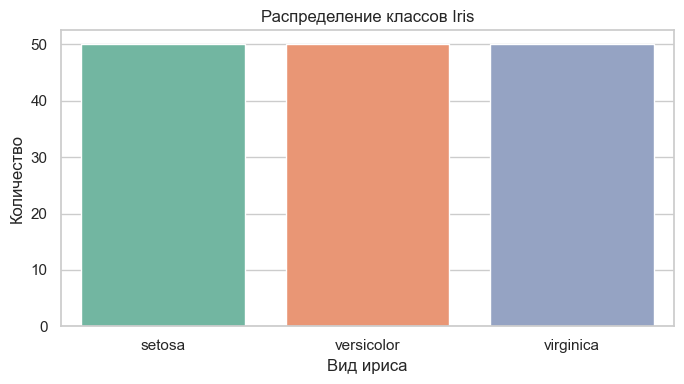

Сохранено: reports\figures\class_distribution.png


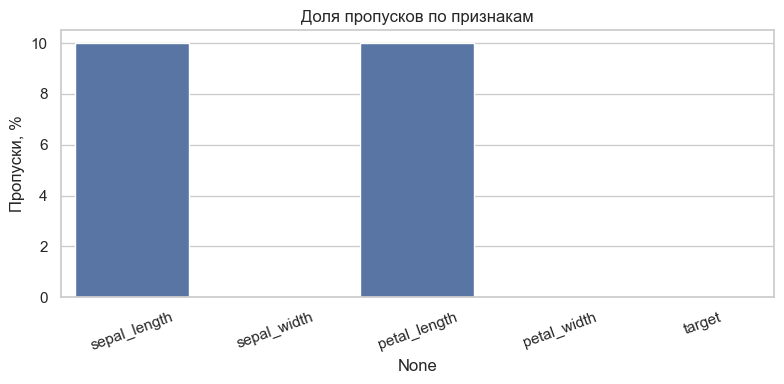

Сохранено: reports\figures\missing_values.png


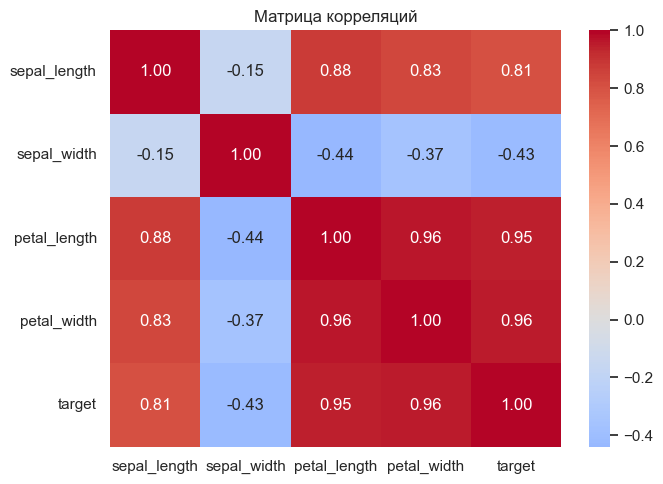

Сохранено: reports\figures\correlation_matrix.png


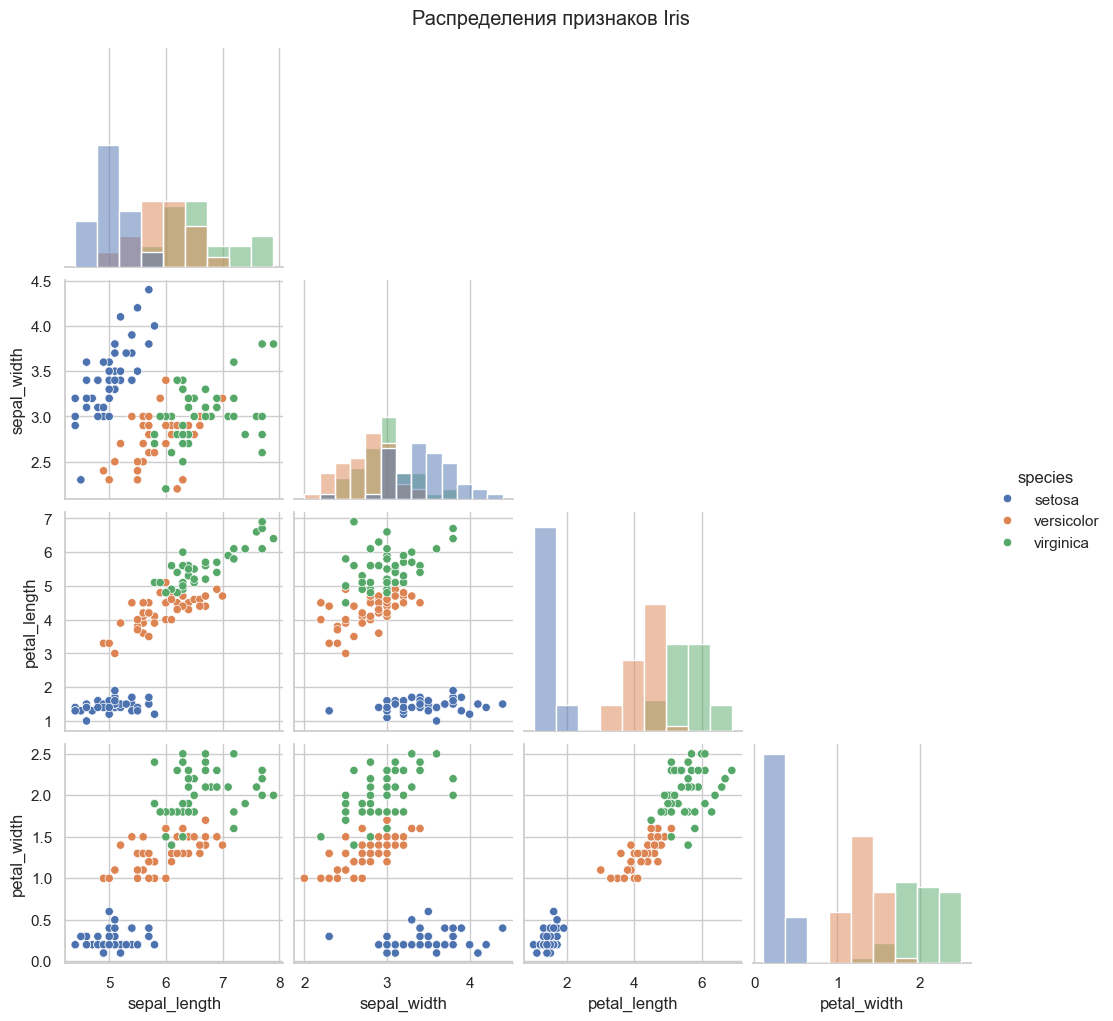

In [5]:
def save_figure(filename: str) -> None:
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Сохранено: {path.relative_to(PROJECT_ROOT)}")

plt.figure(figsize=(7, 4))
classes = df_missing["target"].map(dict(enumerate(iris.target_names)))
sns.countplot(x=classes, hue=classes, palette="Set2", legend=False)
plt.title("Распределение классов Iris"); plt.xlabel("Вид ириса"); plt.ylabel("Количество")
save_figure("class_distribution.png")

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_summary.index, y=missing_summary["missing_percent"], color="#4C72B0")
plt.title("Доля пропусков по признакам"); plt.ylabel("Пропуски, %"); plt.xticks(rotation=20)
save_figure("missing_values.png")

plt.figure(figsize=(7, 5))
sns.heatmap(df_missing.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матрица корреляций")
save_figure("correlation_matrix.png")

plot_df = df_missing.copy()
plot_df["species"] = plot_df["target"].map(dict(enumerate(iris.target_names)))
pair_grid = sns.pairplot(plot_df, vars=feature_names, hue="species", diag_kind="hist", corner=True)
pair_grid.figure.suptitle("Распределения признаков Iris", y=1.02)
pair_grid.figure.savefig(FIGURES_DIR / "feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(pair_grid.figure)

## 6. Разделение на train и test

Разбиение выполняется до обучения преобразований, `stratify` сохраняет классы.

In [6]:
X, y = df_missing[feature_names], df_missing["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
train_df, test_df = X_train.copy(), X_test.copy()
train_df["target"], test_df["target"] = y_train, y_test
train_path, test_path = PROCESSED_DIR / "train.csv", PROCESSED_DIR / "test.csv"
train_df.to_csv(train_path, index=False); test_df.to_csv(test_path, index=False)
print(f"Train: {train_df.shape}; Test: {test_df.shape}")
display(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                      "test": y_test.value_counts().sort_index()}))

Train: (120, 5); Test: (30, 5)


,train,test
target,,
0,40,10
1,40,10
2,40,10


## 7. Кастомный трансформер варианта 10

In [7]:
class PetalRatioTransformer(BaseEstimator, TransformerMixin):
    """Добавляет petal_ratio = petal_length / petal_width."""
    def __init__(self, length_column="petal_length", width_column="petal_width",
                 output_column="petal_ratio"):
        self.length_column = length_column
        self.width_column = width_column
        self.output_column = output_column

    def fit(self, X, y=None):
        self._validate(X)
        return self

    def transform(self, X):
        self._validate(X)
        transformed = X.copy()
        denominator = transformed[self.width_column].replace(0, np.nan)
        transformed[self.output_column] = transformed[self.length_column] / denominator
        return transformed

    def get_feature_names_out(self, input_features=None):
        features = list(input_features) if input_features is not None else feature_names
        return np.asarray(features + [self.output_column], dtype=object)

    def _validate(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Ожидается pandas.DataFrame.")
        missing = {self.length_column, self.width_column} - set(X.columns)
        if missing:
            raise ValueError(f"Отсутствуют колонки: {sorted(missing)}")

transformer_demo = PetalRatioTransformer().fit_transform(X_train.head())
display(transformer_demo)
assert "petal_ratio" in transformer_demo.columns

,sepal_length,sepal_width,petal_length,petal_width,petal_ratio
8,4.4,2.9,1.4,0.2,7.000000
106,NaN,2.5,4.5,1.7,2.647059
76,NaN,2.8,4.8,1.4,3.428571
9,4.9,3.1,NaN,0.1,NaN
89,5.5,2.5,4.0,1.3,3.076923


## 8. ColumnTransformer и итоговый Pipeline

Все признаки Iris числовые. Применяются медианная импутация и StandardScaler.
Категориальная ветка неприменима; при её наличии использовались бы мода и
OneHotEncoder(handle_unknown='ignore').

In [8]:
numeric_features = feature_names + ["petal_ratio"]
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
preprocessor = ColumnTransformer(
    [("numeric", numeric_pipeline, numeric_features)],
    remainder="drop", verbose_feature_names_out=False)
pipeline = Pipeline([
    ("petal_ratio", PetalRatioTransformer()),
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
pipeline

Pipeline(steps=[('petal_ratio', PetalRatioTransformer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['sepal_length',
                                                   'sepal_width',
                                                   'petal_length',
                                                   'petal_width',
                                                   'petal_ratio'])],
                                   verbose_feature_names_out=False)),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

## 9. Подбор гиперпараметров GridSearchCV

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    pipeline,
    {"model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
     "model__class_weight": [None, "balanced"]},
    scoring="accuracy", cv=cv, n_jobs=-1, return_train_score=True)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая CV accuracy: {grid_search.best_score_:.4f}")
grid_results = pd.DataFrame(grid_search.cv_results_).sort_values("rank_test_score")
grid_results.to_csv(REPORTS_DIR / "grid_search_results.csv", index=False)
display(grid_results[["params", "mean_train_score", "mean_test_score",
                      "std_test_score", "rank_test_score"]].head(10))

Лучшие параметры: {'model__C': 1.0, 'model__class_weight': None}
Лучшая CV accuracy: 0.9500


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
4,"{'model__C': 1.0, 'model__class_weight': None}",0.968750,0.950000,0.031180,1
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.968750,0.950000,0.031180,1
6,"{'model__C': 10.0, 'model__class_weight': None}",0.975000,0.941667,0.020412,3
7,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.975000,0.941667,0.020412,3
8,"{'model__C': 100.0, 'model__class_weight': None}",0.977083,0.941667,0.020412,3
9,"{'model__C': 100.0, 'model__class_weight': 'ba...",0.977083,0.941667,0.020412,3
2,"{'model__C': 0.1, 'model__class_weight': None}",0.914583,0.900000,0.050000,7
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.914583,0.900000,0.050000,7
0,"{'model__C': 0.01, 'model__class_weight': None}",0.889583,0.875000,0.026352,9
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.889583,0.875000,0.026352,9


## 10. Оценка на отложенной тестовой выборке

In [10]:
y_pred, y_proba = best_model.predict(X_test), best_model.predict_proba(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
roc_auc_macro = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
metrics = {
    "variant": 10, "dataset": "Iris", "random_state": RANDOM_STATE,
    "train_rows": len(X_train), "test_rows": len(X_test),
    "best_cv_accuracy": round(float(grid_search.best_score_), 6),
    "test_accuracy": round(float(accuracy), 6),
    "test_f1_macro": round(float(f1_macro), 6),
    "test_roc_auc_macro_ovr": round(float(roc_auc_macro), 6),
    "best_params": grid_search.best_params_,
}
print(json.dumps(metrics, ensure_ascii=False, indent=2))
(REPORTS_DIR / "model_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
report_dict = classification_report(y_test, y_pred, target_names=iris.target_names,
                                    output_dict=True, zero_division=0)
classification_df = pd.DataFrame(report_dict).T
classification_df.to_csv(REPORTS_DIR / "classification_report.csv")
display(classification_df)

{
  "variant": 10,
  "dataset": "Iris",
  "random_state": 42,
  "train_rows": 120,
  "test_rows": 30,
  "best_cv_accuracy": 0.95,
  "test_accuracy": 0.966667,
  "test_f1_macro": 0.966583,
  "test_roc_auc_macro_ovr": 0.996667,
  "best_params": {
    "model__C": 1.0,
    "model__class_weight": null
  }
}


,precision,recall,f1-score,support
setosa,1.000000,1.000000,1.000000,10.000000
versicolor,0.909091,1.000000,0.952381,10.000000
virginica,1.000000,0.900000,0.947368,10.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.969697,0.966667,0.966583,30.000000
weighted avg,0.969697,0.966667,0.966583,30.000000


## 11. Матрица ошибок и ROC-кривые

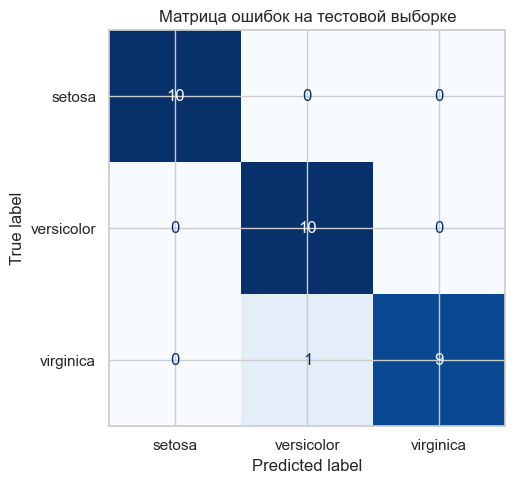

Сохранено: reports\figures\confusion_matrix.png


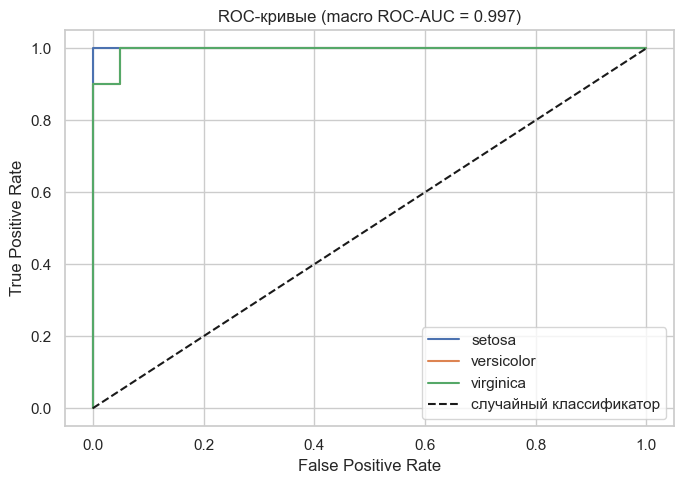

Сохранено: reports\figures\roc_curves.png


In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=iris.target_names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Матрица ошибок на тестовой выборке")
save_figure("confusion_matrix.png")

y_test_binary = label_binarize(y_test, classes=np.arange(len(iris.target_names)))
plt.figure(figsize=(7, 5))
for i, name in enumerate(iris.target_names):
    fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC-кривые (macro ROC-AUC = {roc_auc_macro:.3f})"); plt.legend()
save_figure("roc_curves.png")

## 12. Сохранение и контрольная загрузка модели

Используется формат Pickle через `cloudpickle`: он сохраняет не только
Pipeline, но и определённый в Notebook класс кастомного трансформера. Поэтому
модель можно загрузить в отдельном Python-процессе без повторного объявления
`PetalRatioTransformer`.

In [12]:
model_path = MODELS_DIR / "iris_pipeline.pkl"
with model_path.open("wb") as model_file:
    cloudpickle.dump(best_model, model_file)
with model_path.open("rb") as model_file:
    loaded_model = cloudpickle.load(model_file)
assert np.array_equal(y_pred, loaded_model.predict(X_test))
print(f"Модель сохранена и проверена: {model_path.relative_to(PROJECT_ROOT)}")

Модель сохранена и проверена: models\iris_pipeline.pkl


## 13. DVC: контроль версий данных и модели

Коммиты не создаются автоматически: после проверки выводятся команды Git.

In [13]:
def run_command(command):
    result = subprocess.run(command, cwd=PROJECT_ROOT, text=True, capture_output=True,
                            encoding="utf-8", errors="replace")
    print(f"$ {' '.join(map(str, command))}")
    if result.stdout.strip(): print(result.stdout.strip())
    if result.stderr.strip(): print(result.stderr.strip())
    return result

dvc_version = run_command([sys.executable, "-m", "dvc", "--version"])
dvc_status_text = "DVC недоступен"
if dvc_version.returncode == 0:
    for artifact in (raw_path, train_path, test_path, model_path):
        result = run_command([sys.executable, "-m", "dvc", "add", str(artifact)])
        if result.returncode != 0:
            raise RuntimeError(f"DVC не смог добавить {artifact}")
    dvc_status_result = run_command([sys.executable, "-m", "dvc", "status"])
    dvc_status_text = (dvc_status_result.stdout + dvc_status_result.stderr).strip()
    if dvc_status_result.returncode != 0:
        raise RuntimeError("dvc status завершился с ошибкой")
else:
    print("Установите зависимости: python -m pip install -r requirements.txt")

print("\nПосле проверки: git add .")
print('git commit -m "Complete lab 1 for Iris variant 10"')

$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc --version
3.56.0


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\raw\iris_with_missing.csv
To track the changes with git, run:

	git add 'data\raw\iris_with_missing.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\train.csv
To track the changes with git, run:

	git add 'data\processed\train.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\data\processed\test.csv
To track the changes with git, run:

	git add 'data\processed\test.csv.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc add C:\Users\Доктор Варвар\Desktop\все\MWwithD\models\iris_pipeline.pkl
To track the changes with git, run:

	git add 'models\iris_pipeline.pkl.dvc'

To enable auto staging, run:

	dvc config core.autostage true
\u280b Checking graph


$ C:\Users\Доктор Варвар\Desktop\все\MWwithD\.venv\Scripts\python.exe -m dvc status
data\raw\sample_customers.csv.dvc:
	changed outs:
		not in cache:       data\raw\sample_customers.csv

После проверки: git add .
git commit -m "Complete lab 1 for Iris variant 10"


## 14. Итоговые артефакты и вывод

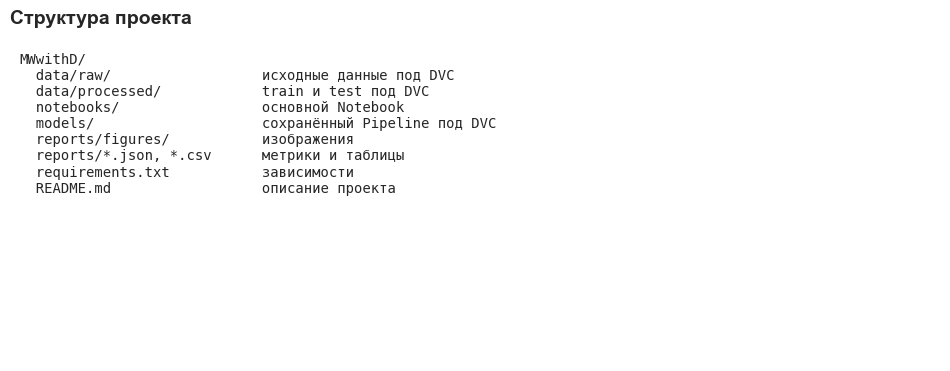

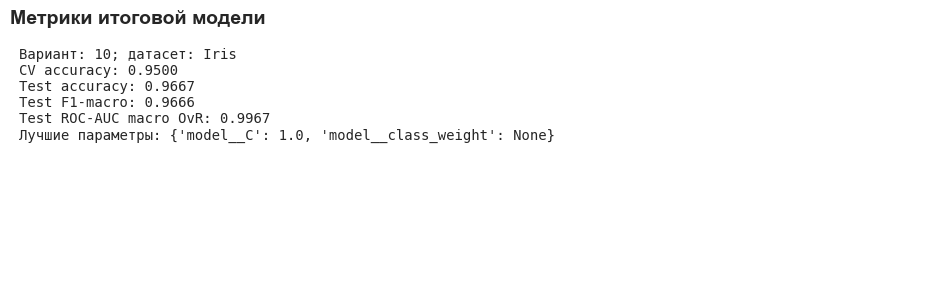

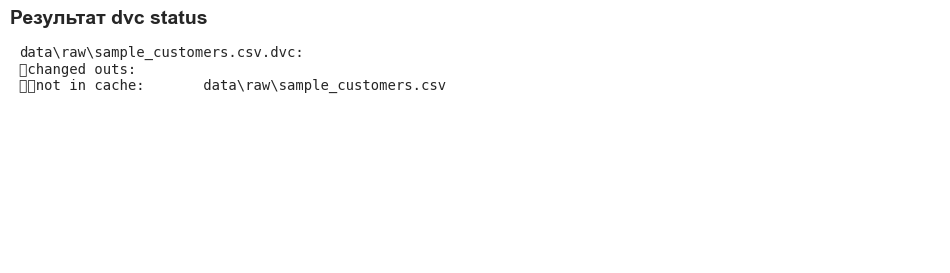

,artifact,exists,size_bytes
0,data\raw\iris_with_missing.csv,True,2818
1,data\processed\train.csv,True,2260
2,data\processed\test.csv,True,616
3,models\iris_pipeline.pkl,True,7113
4,reports\model_metrics.json,True,317
5,reports\classification_report.csv,True,398
6,reports\grid_search_results.csv,True,4011
7,reports\figures\class_distribution.png,True,26382
8,reports\figures\confusion_matrix.png,True,33601
9,reports\figures\correlation_matrix.png,True,74245


Полный аналитический отчёт: reports\lab1_summary.md
Лабораторная работа выполнена успешно.


In [14]:
def save_text_report(text: str, filename: str, title: str) -> None:
    """Сохраняет текстовый результат как изображение для отчёта."""
    lines = text.splitlines() or ["Нет изменений: данные и кэш синхронизированы."]
    height = max(3.0, 0.32 * len(lines) + 1.4)
    fig, ax = plt.subplots(figsize=(12, height))
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold")
    ax.text(0.01, 0.94, "\n".join(lines), va="top", family="monospace", fontsize=10)
    fig.savefig(FIGURES_DIR / filename, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

structure_text = """MWwithD/
  data/raw/                  исходные данные под DVC
  data/processed/            train и test под DVC
  notebooks/                 основной Notebook
  models/                    сохранённый Pipeline под DVC
  reports/figures/           изображения
  reports/*.json, *.csv      метрики и таблицы
  requirements.txt           зависимости
  README.md                  описание проекта"""

metrics_text = "\n".join([
    f"Вариант: 10; датасет: Iris",
    f"CV accuracy: {grid_search.best_score_:.4f}",
    f"Test accuracy: {accuracy:.4f}",
    f"Test F1-macro: {f1_macro:.4f}",
    f"Test ROC-AUC macro OvR: {roc_auc_macro:.4f}",
    f"Лучшие параметры: {grid_search.best_params_}",
])

save_text_report(structure_text, "project_structure.png", "Структура проекта")
save_text_report(metrics_text, "metrics_summary.png", "Метрики итоговой модели")
save_text_report(dvc_status_text, "dvc_status.png", "Результат dvc status")

artifacts = [raw_path, train_path, test_path, model_path,
    REPORTS_DIR / "model_metrics.json", REPORTS_DIR / "classification_report.csv",
    REPORTS_DIR / "grid_search_results.csv", *sorted(FIGURES_DIR.glob("*.png"))]
artifact_table = pd.DataFrame({
    "artifact": [str(p.relative_to(PROJECT_ROOT)) for p in artifacts],
    "exists": [p.exists() for p in artifacts],
    "size_bytes": [p.stat().st_size if p.exists() else 0 for p in artifacts],
})
display(artifact_table)
assert artifact_table["exists"].all()

summary_path = REPORTS_DIR / "lab1_summary.md"
cm = confusion_matrix(y_test, y_pred)
best_row = grid_results.iloc[0]
petal_correlation = df_missing["petal_length"].corr(df_missing["petal_width"])
missing_total = int(df_missing[missing_columns].isna().sum().sum())
dvc_analysis = (
    "Новые артефакты Iris синхронизированы с локальным DVC-кэшем. "
    "Сообщение `not in cache` относится только к старому `sample_customers.csv`, "
    "который находился в репозитории до выполнения лабораторной."
    if "sample_customers" in dvc_status_text
    else "DVC не обнаружил изменений в контролируемых артефактах лабораторной."
)

summary_path.write_text(f"""# Отчёт по лабораторной работе №1

## Постановка задачи

Выполнен вариант 10 на датасете **Iris**. Требовалось построить воспроизводимый
конвейер многоклассовой классификации, использовать Git и DVC, обработать
пропуски, реализовать собственный трансформер и сохранить обученную модель.
Целевая переменная `target` принимает три значения: setosa, versicolor и
virginica.

## Подготовка данных

Исходный Iris содержит 150 наблюдений, четыре числовых признака и не содержит
пропусков. В каждом классе находится по 50 объектов, поэтому выборка
сбалансирована и применение `class_weight='balanced'` не является обязательным.

Для выполнения условия задания в `sepal_length` и `petal_length` было
воспроизводимо внесено по {n_missing} пропусков — ровно 10% значений каждой
колонки. Всего создано {missing_total} пропущенных значений. Целевая переменная
не изменялась. После стратифицированного разбиения получено {len(X_train)}
объектов для обучения и {len(X_test)} объектов для итогового тестирования; в
тестовой выборке осталось по 10 объектов каждого класса.

## Анализ признаков

Наиболее сильная связь наблюдается между длиной и шириной лепестка: коэффициент
корреляции составляет {petal_correlation:.3f}. Это согласуется с графиками
распределений: setosa хорошо отделяется от остальных видов по параметрам
лепестка, тогда как области versicolor и virginica частично пересекаются.
Следовательно, основная сложность классификации связана именно с различением
versicolor и virginica.

Кастомный `PetalRatioTransformer` создаёт признак `petal_ratio` как отношение
длины лепестка к его ширине. Он добавляет относительную характеристику формы
лепестка, которую исходные абсолютные размеры не выражают напрямую. Деление на
ноль безопасно преобразуется в пропуск. Корректность создания нового признака
проверена перед включением трансформера в общий Pipeline.

## Построенный конвейер

Итоговый Pipeline выполняет следующие операции:

1. создаёт `petal_ratio` кастомным трансформером;
2. заполняет пропуски медианами, рассчитанными только на train;
3. стандартизирует пять числовых признаков;
4. выполняет классификацию логистической регрессией.

Все признаки Iris числовые, поэтому категориальная ветка `ColumnTransformer`
для этого варианта не применяется. Все преобразования находятся внутри
Pipeline, что предотвращает утечку данных при кросс-валидации и тестировании.

## Подбор гиперпараметров

GridSearchCV использовал стратифицированную 5-фолдовую кросс-валидацию.
Проверялись значения `C = 0.01, 0.1, 1, 10, 100` и варианты с весами классов и
без них. Лучшие параметры: `{grid_search.best_params_}`.

Средняя accuracy лучшей конфигурации на обучающих частях фолдов равна
{float(best_row['mean_train_score']):.4f}, а на валидационных —
{grid_search.best_score_:.4f} ± {float(best_row['std_test_score']):.4f}.
Разница невелика, поэтому выраженных признаков переобучения не наблюдается.
Одинаковый результат вариантов с `class_weight=None` и `balanced` ожидаем,
поскольку классы исходно представлены поровну.

## Результаты на тестовой выборке

| Метрика | Значение |
|---|---:|
| Accuracy | {accuracy:.4f} |
| F1-macro | {f1_macro:.4f} |
| ROC-AUC macro OvR | {roc_auc_macro:.4f} |

Модель правильно классифицировала {int(np.trace(cm))} из {len(y_test)} тестовых
объектов. Единственная ошибка: один объект virginica отнесён к versicolor.
Setosa и versicolor распознаны полностью. Для setosa F1 равен
{classification_df.loc['setosa', 'f1-score']:.4f}, для versicolor —
{classification_df.loc['versicolor', 'f1-score']:.4f}, для virginica —
{classification_df.loc['virginica', 'f1-score']:.4f}. Ошибка между двумя
близкими видами соответствует пересечению их областей на графиках признаков.

ROC-AUC {roc_auc_macro:.4f} показывает, что модель почти идеально ранжирует
объекты правильного класса относительно остальных. Accuracy и F1-macro почти
совпадают, что дополнительно подтверждает отсутствие перекоса качества в
сторону одного класса.

## Воспроизводимость и сохранение результатов

Во всех случайных операциях используется `random_state={RANDOM_STATE}`.
Зависимости зафиксированы в `requirements.txt`. Полный Pipeline сохранён в
`models/iris_pipeline.pkl` через cloudpickle и успешно загружен повторно;
предсказания до и после загрузки совпали. Исходные данные, train/test и модель
добавлены под контроль DVC. {dvc_analysis}

Таблицы метрик находятся в `reports`, графики — в `reports/figures`, а описание
всех каталогов и инструкция запуска приведены в `README.md`.

## Соответствие требованиям лабораторной работы

- Использована предусмотренная вариантом 10 выборка Iris.
- Поскольку исходные данные не содержат пропусков, в две числовые колонки
  искусственно внесено по 10% пропущенных значений.
- Реализован собственный трансформер на основе `BaseEstimator` и
  `TransformerMixin`, вычисляющий `petal_length / petal_width`.
- Предобработка выполнена через `ColumnTransformer`: пропуски заполняются
  медианой, после чего применяется `StandardScaler`.
- Предобработка и логистическая регрессия объединены в единый Pipeline.
- Выполнено стратифицированное разбиение 80/20 с `random_state=42`.
- Проведён GridSearchCV, выведены лучшие параметры и результаты пятифолдовой
  кросс-валидации.
- Рассчитаны accuracy, F1-macro, ROC-AUC и матрица ошибок.
- Модель сохранена в `models`, метрики и изображения — в `reports`.
- Исходные данные, train/test и модель добавлены под контроль DVC.

## Вывод

Цель работы достигнута: создан воспроизводимый конвейер, объединяющий генерацию
признака, импутацию, масштабирование и классификацию. Модель показала высокое и
устойчивое качество: CV accuracy {grid_search.best_score_:.4f}, test accuracy
{accuracy:.4f} и ROC-AUC {roc_auc_macro:.4f}. Наиболее уверенно отделяется
setosa; единственная ошибка возникла между похожими классами versicolor и
virginica. Все обязательные этапы варианта 10 выполнены, результаты и
артефакты сохранены в предусмотренной структуре проекта.
""", encoding="utf-8")
print(f"Полный аналитический отчёт: {summary_path.relative_to(PROJECT_ROOT)}")
print("Лабораторная работа выполнена успешно.")